# Uncertainty of the ground conductivity

A thermal response test gives the ground thermal conductivity with some uncertainty, and the length
of the field depends on it. This notebook sizes the office building of `demo_project.py` for
conductivities from 1.5 to 3.5 W/m·K and plots the total borehole length each mode requires. It is
the notebook version of `conductivity_uncertainty.py`.

Run it from the `examples` folder, with the executable and a licence (see
[Installation](../docs/install.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()

## One sizing per conductivity

`ga.sweep` builds one copy of the project per value, sizes them in parallel and returns a table.

In [2]:
conductivities = np.arange(1.5, 3.51, 0.25)          # W/m·K

p = make_project()
study = ga.sweep(p, {"ground_heat_exchanger.ground_thermal_conductivity": conductivities}, "size")
study[["ground_heat_exchanger.ground_thermal_conductivity", "governing_mode",
       "governing_total_borehole_length"]].round(1)

,ground_heat_exchanger.ground_thermal_conductivity,governing_mode,governing_total_borehole_length
0,1.5,heating,1224.3
1,1.8,heating,1162.2
2,2.0,heating,1106.8
3,2.2,heating,1057.4
4,2.5,heating,1013.3
5,2.8,heating,973.7
6,3.0,heating,938.1
7,3.2,heating,906.0
8,3.5,heating,876.9


## Figure

Heating governs over the whole range. The length falls as the conductivity rises, quickly at first
and then more slowly.

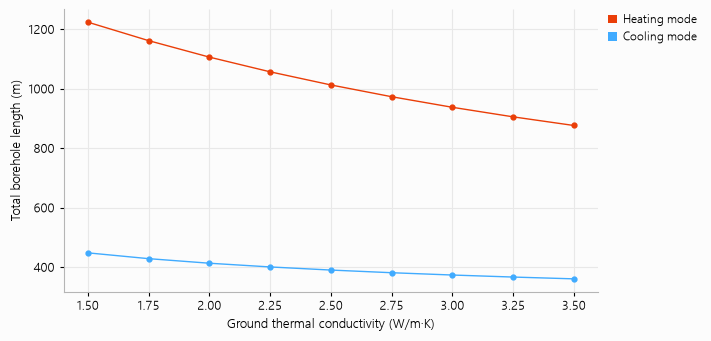

In [3]:
fig, ax = ghe.figure(width=7.0)
ghe.mode_lines(ax, conductivities, study["total_borehole_length_heating"],
               study["total_borehole_length_cooling"])
ghe.axis_titles(ax, "Ground thermal conductivity (W/m·K)", "Total borehole length (m)")
plt.show()